# Prediksi Fair Market Value Pemain Sepak Bola & Deteksi Pemain Undervalued

Pipeline *end-to-end* berbasis dataset Transfermarkt untuk menaksir harga pasar wajar (*fair market value*) menggunakan komparasi **Linear Regression**, **Random Forest Regressor**, dan **XGBoost Regressor**, serta mengidentifikasi pemain berstatus **Undervalued** (konsep *Moneyball*).

**Struktur Notebook:**
1. **Bagian 1:** EDA & Uji Korelasi
2. **Bagian 2:** Data Cleaning, Feature Selection & Preprocessing
3. **Bagian 3:** Modelling & Evaluasi
4. **Bagian 4:** Feature Importance & Deteksi Undervalued

In [1]:
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110

RAW_DATA_DIR = Path("../dataset")
PROCESSED_DATA_DIR = Path("../dataset/processed")
MODELS_DIR = Path("../models")

os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

RANDOM_STATE = 42
print("Setup selesai. Direktori output siap digunakan.")

Setup selesai. Direktori output siap digunakan.


## Bagian 1: EDA & Uji Korelasi

Tahap ini memuat tabel-tabel relevan dari dataset Transfermarkt (`players.csv`, `appearances.csv`, `clubs.csv`, `competitions.csv`, `player_valuations.csv`), melakukan agregasi performa ke level pemain, memeriksa kualitas data (*missing values*, duplikat, tipe data, *outliers*), menganalisis distribusi target `market_value_in_eur`, dan menguji korelasi Pearson serta Spearman.

In [2]:
def load_raw_tables(data_dir: Path) -> dict[str, pd.DataFrame]:
    tables = {
        "players": pd.read_csv(data_dir / "players.csv", low_memory=False),
        "appearances": pd.read_csv(data_dir / "appearances.csv", low_memory=False),
        "clubs": pd.read_csv(data_dir / "clubs.csv", low_memory=False),
        "competitions": pd.read_csv(data_dir / "competitions.csv", low_memory=False),
        "valuations": pd.read_csv(data_dir / "player_valuations.csv", low_memory=False),
    }
    return tables


raw_tables = load_raw_tables(RAW_DATA_DIR)
for name, df_tab in raw_tables.items():
    print(f"{name:15s} -> shape: {df_tab.shape[0]:>9,d} baris x {df_tab.shape[1]:>2d} kolom")

players         -> shape:    50,149 baris x 26 kolom
appearances     -> shape: 1,894,350 baris x 13 kolom
clubs           -> shape:       796 baris x 17 kolom
competitions    -> shape:        65 baris x 11 kolom
valuations      -> shape:   656,301 baris x  6 kolom


In [3]:
def build_player_level_dataset(tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    players = tables["players"].copy()
    apps = tables["appearances"].copy()
    clubs = tables["clubs"].copy()
    comps = tables["competitions"].copy()
    vals = tables["valuations"].copy()

    apps["is_cl"] = (apps["competition_id"] == "CL").astype(int)
    apps["is_el"] = (apps["competition_id"] == "EL").astype(int)

    app_agg = (
        apps.groupby("player_id", as_index=False)
        .agg(
            total_matches=("appearance_id", "count"),
            total_minutes=("minutes_played", "sum"),
            total_goals=("goals", "sum"),
            total_assists=("assists", "sum"),
            total_yellow_cards=("yellow_cards", "sum"),
            total_red_cards=("red_cards", "sum"),
            cl_appearances=("is_cl", "sum"),
            el_appearances=("is_el", "sum"),
        )
    )

    vals["date"] = pd.to_datetime(vals["date"], errors="coerce")
    latest_val = (
        vals.sort_values("date")
        .groupby("player_id", as_index=False)
        .last()[["player_id", "date"]]
        .rename(columns={"date": "latest_valuation_date"})
    )

    club_cols = clubs[
        [
            "club_id",
            "squad_size",
            "average_age",
            "foreigners_percentage",
            "national_team_players",
            "stadium_seats",
        ]
    ].rename(
        columns={
            "club_id": "current_club_id",
            "squad_size": "club_squad_size",
            "average_age": "club_average_age",
            "foreigners_percentage": "club_foreigners_pct",
            "national_team_players": "club_national_team_players",
            "stadium_seats": "club_stadium_seats",
        }
    )

    comp_cols = comps[["competition_id", "type", "sub_type", "country_name"]].rename(
        columns={
            "competition_id": "current_club_domestic_competition_id",
            "type": "competition_type",
            "sub_type": "competition_sub_type",
            "country_name": "league_country",
        }
    )

    merged = (
        players.merge(app_agg, on="player_id", how="left")
        .merge(latest_val, on="player_id", how="left")
        .merge(club_cols, on="current_club_id", how="left")
        .merge(comp_cols, on="current_club_domestic_competition_id", how="left")
    )
    return merged


df_raw = build_player_level_dataset(raw_tables)
print(f"Dataset gabungan level pemain: {df_raw.shape[0]:,d} baris x {df_raw.shape[1]} kolom")
display(df_raw.head(3))

Dataset gabungan level pemain: 50,149 baris x 43 kolom


,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,contract_expiration_date,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur,total_matches,total_minutes,total_goals,total_assists,total_yellow_cards,total_red_cards,cl_appearances,el_appearances,latest_valuation_date,club_squad_size,club_average_age,club_foreigners_pct,club_national_team_players,club_stadium_seats,competition_type,competition_sub_type,league_country
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,1978-06-09 00:00:00,Centre-Forward,Attack,right,184.00,NaN,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,"1,000,000.00","30,000,000.00",136.00,"8,808.00",48.00,25.00,19.00,0.00,0.00,11.00,2016-01-04,28.00,27.80,60.70,11.00,"70,634.00",domestic_league,first_tier,Italy
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,1980-08-06 00:00:00,Goalkeeper,Goalkeeper,left,190.00,NaN,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,"750,000.00","8,000,000.00",152.00,"13,508.00",0.00,0.00,4.00,2.00,32.00,10.00,2017-12-28,29.00,24.80,55.20,15.00,"81,365.00",domestic_league,first_tier,Germany
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,1981-01-30 00:00:00,Centre-Forward,Attack,NaN,NaN,NaN,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,"1,000,000.00","34,500,000.00",122.00,"8,788.00",38.00,13.00,11.00,1.00,9.00,5.00,2016-06-21,31.00,28.00,58.10,10.00,"28,703.00",domestic_league,first_tier,Greece


In [4]:
print(f"Jumlah duplikat baris penuh : {df_raw.duplicated().sum()}")
print(f"Jumlah duplikat player_id   : {df_raw['player_id'].duplicated().sum()}")

audit_df = pd.DataFrame(
    {
        "dtype": df_raw.dtypes.astype(str),
        "non_null": df_raw.notna().sum(),
        "missing_count": df_raw.isna().sum(),
        "missing_pct": (df_raw.isna().mean() * 100).round(2),
        "nunique": df_raw.nunique(dropna=True),
    }
).sort_values("missing_pct", ascending=False)

display(audit_df[audit_df["missing_count"] > 0])

Jumlah duplikat baris penuh : 0
Jumlah duplikat player_id   : 0


,dtype,non_null,missing_count,missing_pct,nunique
current_national_team_id,float64,3260,46889,93.50,123
international_caps,float64,19356,30793,61.40,159
international_goals,float64,19356,30793,61.40,68
agent_name,str,26853,23296,46.45,3954
total_goals,float64,29530,20619,41.12,189
total_assists,float64,29530,20619,41.12,134
total_matches,float64,29530,20619,41.12,532
total_minutes,float64,29530,20619,41.12,10879
cl_appearances,float64,29530,20619,41.12,107
el_appearances,float64,29530,20619,41.12,62


,feature,min,median,q3,max,iqr_upper,outliers_count,outliers_pct
0,market_value_in_eur,"10,000.00","275,000.00","700,000.00","200,000,000.00","1,600,000.00",5799,13.96
1,height_in_cm,17.00,182.00,187.00,210.00,202.00,102,0.22
2,total_matches,1.00,28.00,88.00,665.00,211.00,2209,7.48
3,total_minutes,1.00,"1,611.50","5,890.75","54,203.00","14,342.88",2493,8.44
4,total_goals,0.00,1.00,5.00,528.00,12.50,3754,12.71
5,total_assists,0.00,1.00,4.00,224.00,10.00,3918,13.27
6,total_yellow_cards,0.00,3.00,12.00,147.00,30.00,2502,8.47
7,total_red_cards,0.00,0.00,0.00,8.00,0.00,4753,16.10
8,club_national_team_players,0.00,3.00,6.00,24.00,13.50,3306,7.01
9,club_stadium_seats,0.00,"20,356.00","32,830.00","87,523.00","65,324.50",1833,3.89


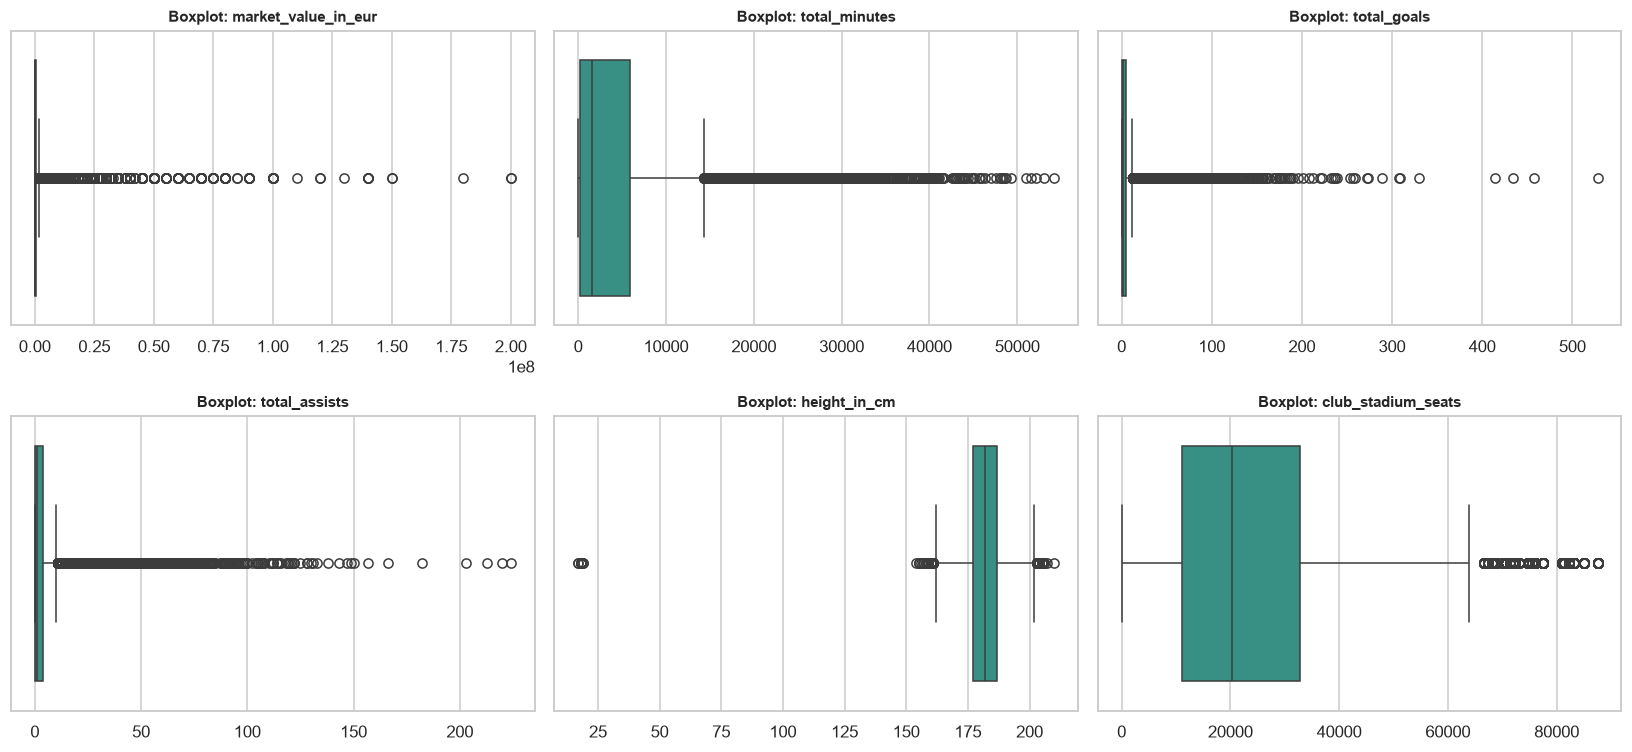

In [5]:
eda_numeric_cols = [
    "market_value_in_eur",
    "height_in_cm",
    "total_matches",
    "total_minutes",
    "total_goals",
    "total_assists",
    "total_yellow_cards",
    "total_red_cards",
    "club_national_team_players",
    "club_stadium_seats",
]

outlier_rows = []
for col in eda_numeric_cols:
    series = df_raw[col].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()
    outlier_rows.append(
        {
            "feature": col,
            "min": series.min(),
            "median": series.median(),
            "q3": q3,
            "max": series.max(),
            "iqr_upper": upper,
            "outliers_count": int(n_out),
            "outliers_pct": round(n_out / len(series) * 100, 2),
        }
    )

display(pd.DataFrame(outlier_rows))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
plot_cols = [
    "market_value_in_eur",
    "total_minutes",
    "total_goals",
    "total_assists",
    "height_in_cm",
    "club_stadium_seats",
]
for ax, col in zip(axes.ravel(), plot_cols):
    sns.boxplot(x=df_raw[col].dropna(), ax=ax, color="#2a9d8f")
    ax.set_title(f"Boxplot: {col}", fontsize=10, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

Sebelum log1p -> Mean: €1,511,049 | Median: €275,000 | Skewness: 11.75 | Kurtosis: 217.55
Sesudah log1p -> Mean: 12.690 | Median: 12.525 | Skewness: 0.70 | Kurtosis: 0.69


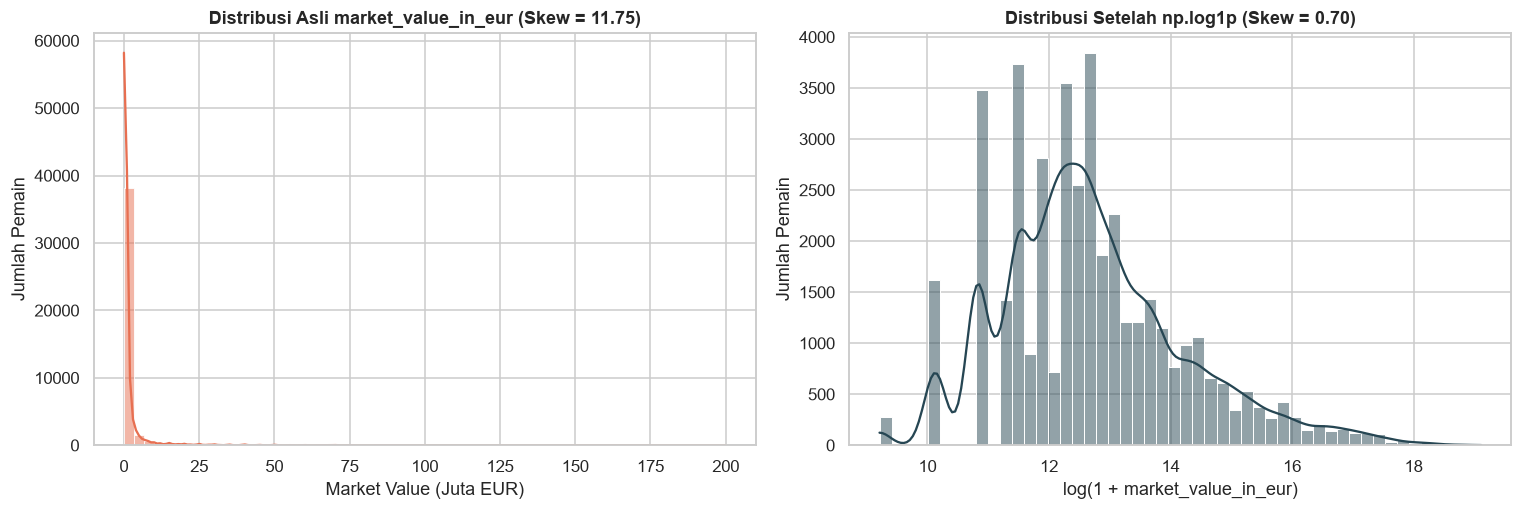

In [6]:
target_valid = df_raw["market_value_in_eur"].dropna()
target_log = np.log1p(target_valid)

print(
    f"Sebelum log1p -> Mean: €{target_valid.mean():,.0f} | Median: €{target_valid.median():,.0f} "
    f"| Skewness: {target_valid.skew():.2f} | Kurtosis: {target_valid.kurtosis():.2f}"
)
print(
    f"Sesudah log1p -> Mean: {target_log.mean():.3f} | Median: {target_log.median():.3f} "
    f"| Skewness: {target_log.skew():.2f} | Kurtosis: {target_log.kurtosis():.2f}"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.histplot(target_valid / 1e6, bins=60, kde=True, ax=axes[0], color="#e76f51")
axes[0].set_title(f"Distribusi Asli market_value_in_eur (Skew = {target_valid.skew():.2f})", fontweight="bold")
axes[0].set_xlabel("Market Value (Juta EUR)")
axes[0].set_ylabel("Jumlah Pemain")

sns.histplot(target_log, bins=50, kde=True, ax=axes[1], color="#264653")
axes[1].set_title(f"Distribusi Setelah np.log1p (Skew = {target_log.skew():.2f})", fontweight="bold")
axes[1].set_xlabel("log(1 + market_value_in_eur)")
axes[1].set_ylabel("Jumlah Pemain")

plt.tight_layout()
plt.show()

,pearson_raw_eur,spearman_raw_eur,pearson_log_eur,spearman_log_eur
total_matches,0.24,0.35,0.34,0.35
total_minutes,0.23,0.33,0.31,0.33
total_goals,0.26,0.33,0.26,0.33
total_assists,0.27,0.33,0.29,0.33
cl_appearances,0.36,0.32,0.31,0.32
total_yellow_cards,0.17,0.29,0.25,0.29
club_national_team_players,0.33,0.28,0.33,0.28
el_appearances,0.18,0.28,0.27,0.28
club_stadium_seats,0.23,0.22,0.26,0.22
international_caps,0.15,0.19,0.14,0.19


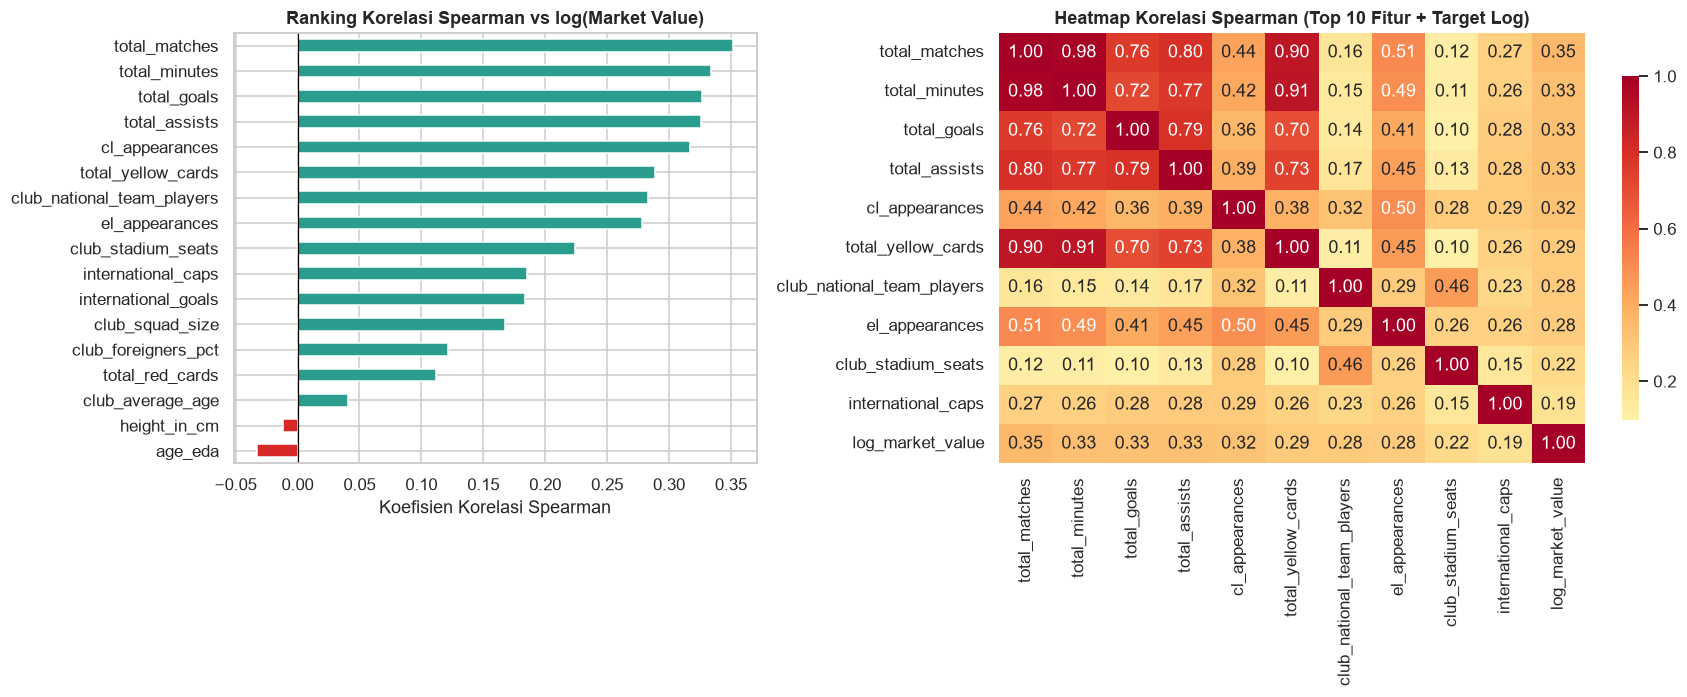

In [7]:
corr_df = df_raw.copy()
corr_df["date_of_birth"] = pd.to_datetime(corr_df["date_of_birth"], errors="coerce")
corr_df["ref_date"] = corr_df["latest_valuation_date"].fillna(pd.Timestamp("2025-06-30"))
corr_df["age_eda"] = (corr_df["ref_date"] - corr_df["date_of_birth"]).dt.days / 365.25
corr_df["log_market_value"] = np.log1p(corr_df["market_value_in_eur"])

candidate_num_cols = [
    "age_eda",
    "height_in_cm",
    "international_caps",
    "international_goals",
    "total_matches",
    "total_minutes",
    "total_goals",
    "total_assists",
    "total_yellow_cards",
    "total_red_cards",
    "cl_appearances",
    "el_appearances",
    "club_squad_size",
    "club_average_age",
    "club_foreigners_pct",
    "club_national_team_players",
    "club_stadium_seats",
]

corr_subset = corr_df[candidate_num_cols + ["market_value_in_eur", "log_market_value"]].dropna(
    subset=["market_value_in_eur"]
)

corr_ranking = pd.DataFrame(
    {
        "pearson_raw_eur": corr_subset[candidate_num_cols].corrwith(corr_subset["market_value_in_eur"], method="pearson"),
        "spearman_raw_eur": corr_subset[candidate_num_cols].corrwith(corr_subset["market_value_in_eur"], method="spearman"),
        "pearson_log_eur": corr_subset[candidate_num_cols].corrwith(corr_subset["log_market_value"], method="pearson"),
        "spearman_log_eur": corr_subset[candidate_num_cols].corrwith(corr_subset["log_market_value"], method="spearman"),
    }
).sort_values("spearman_log_eur", key=lambda s: s.abs(), ascending=False)

display(corr_ranking.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.4]})

corr_plot = corr_ranking["spearman_log_eur"].sort_values()
colors = ["#d62828" if v < 0 else "#2a9d8f" for v in corr_plot]
corr_plot.plot(kind="barh", ax=axes[0], color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Ranking Korelasi Spearman vs log(Market Value)", fontweight="bold")
axes[0].set_xlabel("Koefisien Korelasi Spearman")

top_features_for_heatmap = list(corr_ranking.head(10).index) + ["log_market_value"]
heatmap_matrix = corr_subset[top_features_for_heatmap].corr(method="spearman")
sns.heatmap(
    heatmap_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    ax=axes[1],
    cbar_kws={"shrink": 0.8},
)
axes[1].set_title("Heatmap Korelasi Spearman (Top 10 Fitur + Target Log)", fontweight="bold")

plt.tight_layout()
plt.show()

### Ringkasan Temuan Bagian 1
- **Struktur & Kualitas Data:** Dataset gabungan mencakup 50.149 pemain unik tanpa duplikat `player_id`. Beberapa kolom memiliki *missing values* cukup tinggi (`contract_expiration_date` ~37%, `international_caps` ~61%, serta `market_value_in_eur` ~17% untuk pemain non-aktif/lama).
- **Transformasi Target:** `market_value_in_eur` sangat *right-skewed* (skewness > 5). Transformasi `np.log1p` menormalkan distribusi secara drastis sehingga lebih sesuai untuk pemodelan regresi.
- **Hasil Uji Korelasi:** Fitur dengan korelasi terkuat terhadap `log_market_value` adalah reputasi klub (`club_national_team_players`, `club_stadium_seats`, `club_foreigners_pct`), pengalaman kompetisi elit (`cl_appearances`, `el_appearances`), volume menit bermain (`total_minutes`, `total_matches`), serta kontribusi ofensif (`total_goals`, `total_assists`) dan pengalaman internasional (`international_caps`). Usia (`age_eda`) menunjukkan hubungan negatif pada skala linear/monotonic karena pemain senior cenderung mengalami penurunan valuasi setelah puncak karier.

## Bagian 2: Data Cleaning, Feature Selection & Preprocessing

Tahap ini membersihkan data secara terukur, membangun fitur turunan berbasis domain *scouting*, memvalidasi pemilihan fitur agar bebas multikolinearitas berlebih serta *data leakage* (misal mengecualikan `highest_market_value_in_eur`), melakukan *encoding*, dan menyimpan dataset siap latih ke `dataset/processed/players_clean.csv`.

In [8]:
def clean_and_engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Filter pemain aktif (musim >= 2024), memiliki valuasi valid, posisi jelas, dan minimal 270 menit bermain
    df = df[
        (df["last_season"] >= 2024)
        & (df["market_value_in_eur"].notna())
        & (df["market_value_in_eur"] > 0)
        & (df["date_of_birth"].notna())
        & (df["position"].notna())
        & (df["position"] != "Missing")
        & (df["total_minutes"].fillna(0) >= 270)
    ].copy()

    df["date_of_birth"] = pd.to_datetime(df["date_of_birth"], errors="coerce")
    df["contract_expiration_date"] = pd.to_datetime(df["contract_expiration_date"], errors="coerce")
    df["latest_valuation_date"] = pd.to_datetime(df["latest_valuation_date"], errors="coerce")
    ref_date = df["latest_valuation_date"].fillna(pd.Timestamp("2025-06-30"))

    # Feature engineering: usia, sisa kontrak, statistik per-90 menit, dan indikator level klub/liga
    df["age"] = ((ref_date - df["date_of_birth"]).dt.days / 365.25).clip(15.0, 45.0)

    contract_months = (df["contract_expiration_date"] - ref_date).dt.days / 30.44
    df["contract_months_left"] = contract_months.clip(0.0, 72.0)
    df["contract_months_left"] = df["contract_months_left"].fillna(df["contract_months_left"].median())

    nineties = df["total_minutes"] / 90.0
    df["goals_per_90"] = df["total_goals"].fillna(0) / nineties
    df["assists_per_90"] = df["total_assists"].fillna(0) / nineties
    df["yellow_cards_per_90"] = df["total_yellow_cards"].fillna(0) / nineties
    df["red_cards_per_90"] = df["total_red_cards"].fillna(0) / nineties
    df["minutes_per_match"] = df["total_minutes"] / df["total_matches"].clip(lower=1)

    top5_leagues = {"GB1", "ES1", "IT1", "L1", "FR1"}
    df["is_top5_league"] = df["current_club_domestic_competition_id"].isin(top5_leagues).astype(int)

    major_leagues = {
        "GB1", "ES1", "IT1", "L1", "FR1", "NL1", "PO1", "BE1",
        "TR1", "RU1", "SC1", "GR1", "DK1", "UKR1",
    }
    comp_id = df["current_club_domestic_competition_id"].astype("string").fillna("Other")
    df["league_group"] = np.where(comp_id.isin(major_leagues), comp_id, "Other")

    # Imputasi missing values terukur
    df["international_caps"] = df["international_caps"].fillna(0)
    df["cl_appearances"] = df["cl_appearances"].fillna(0)
    df["el_appearances"] = df["el_appearances"].fillna(0)
    df["foot"] = df["foot"].astype("string").fillna("unknown")
    df["position"] = df["position"].astype("string")
    df["current_club_name"] = df["current_club_name"].astype("string").fillna("Unknown")

    df["height_in_cm"] = df["height_in_cm"].fillna(
        df.groupby("position")["height_in_cm"].transform("median")
    )
    df["height_in_cm"] = df["height_in_cm"].fillna(df["height_in_cm"].median()).clip(155.0, 210.0)

    for col in ["club_national_team_players", "club_stadium_seats", "club_foreigners_pct"]:
        df[col] = df[col].fillna(df[col].median())

    # Penanganan outlier ekstrem pada metrik rasio per-90 (winsorizing persentil ke-99)
    for col in ["goals_per_90", "assists_per_90", "yellow_cards_per_90", "red_cards_per_90"]:
        upper_cap = df[col].quantile(0.99)
        df[col] = df[col].clip(lower=0.0, upper=upper_cap)

    df["log_market_value"] = np.log1p(df["market_value_in_eur"])
    return df


df_clean_all = clean_and_engineer_features(df_raw)
print(f"Jumlah pemain setelah cleaning & filtering: {len(df_clean_all):,d} (dari {len(df_raw):,d})")

Jumlah pemain setelah cleaning & filtering: 10,281 (dari 50,149)


Pasangan fitur dengan |korelasi Pearson| > 0.85: Tidak ada (aman dari multikolinearitas tinggi)


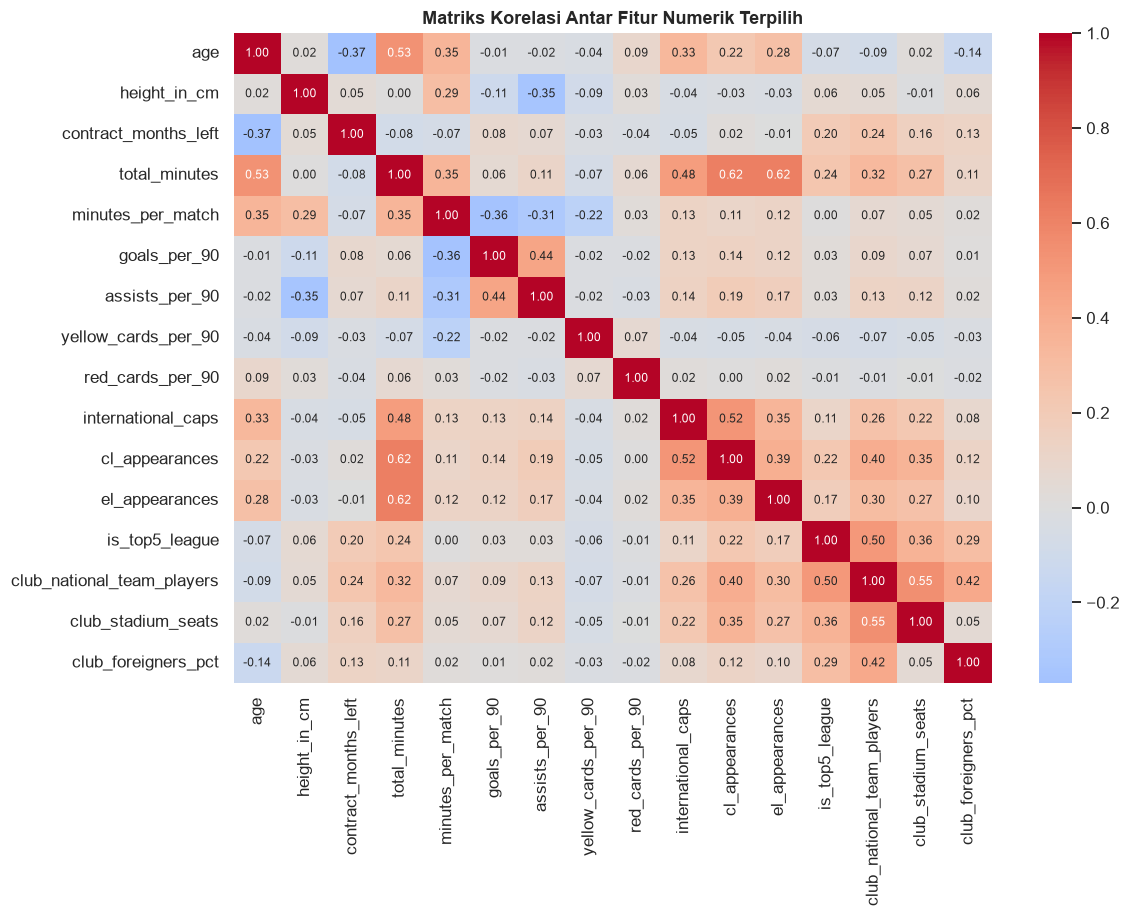

In [9]:
# Seleksi fitur final berbasis uji korelasi & literatur (Müller et al., 2017; Fotache et al., 2026; Lubis et al.)
# Catatan anti-leakage: 'highest_market_value_in_eur' dan 'market_value_in_eur' TIDAK dimasukkan ke fitur X.
# Catatan anti-multikolinearitas: memakai rasio per-90 & 'total_minutes' sebagai pengganti hitungan mentah yang redundant.

NUMERIC_FEATURES = [
    "age",
    "height_in_cm",
    "contract_months_left",
    "total_minutes",
    "minutes_per_match",
    "goals_per_90",
    "assists_per_90",
    "yellow_cards_per_90",
    "red_cards_per_90",
    "international_caps",
    "cl_appearances",
    "el_appearances",
    "is_top5_league",
    "club_national_team_players",
    "club_stadium_seats",
    "club_foreigners_pct",
]

CATEGORICAL_FEATURES = ["position", "foot", "league_group"]
METADATA_COLS = ["player_id", "name", "current_club_name", "last_season"]
TARGET_COL = "market_value_in_eur"
LOG_TARGET_COL = "log_market_value"

# Cek multikolinearitas antar fitur numerik terpilih (threshold |r| > 0.85)
feat_corr = df_clean_all[NUMERIC_FEATURES].corr(method="pearson")
high_corr_pairs = []
for i in range(len(NUMERIC_FEATURES)):
    for j in range(i + 1, len(NUMERIC_FEATURES)):
        r_val = feat_corr.iloc[i, j]
        if abs(r_val) > 0.85:
            high_corr_pairs.append((NUMERIC_FEATURES[i], NUMERIC_FEATURES[j], round(r_val, 3)))

print("Pasangan fitur dengan |korelasi Pearson| > 0.85:", high_corr_pairs if high_corr_pairs else "Tidak ada (aman dari multikolinearitas tinggi)")

plt.figure(figsize=(11, 8.5))
sns.heatmap(feat_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Matriks Korelasi Antar Fitur Numerik Terpilih", fontweight="bold")
plt.tight_layout()
plt.show()

In [10]:
selected_cols = METADATA_COLS + NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET_COL, LOG_TARGET_COL]
df_clean = df_clean_all[selected_cols].reset_index(drop=True)

for cat_col in CATEGORICAL_FEATURES:
    df_clean[cat_col] = df_clean[cat_col].astype(str)

# Demonstrasi preview encoding one-hot sebelum disimpan
ohe_preview = pd.get_dummies(df_clean[CATEGORICAL_FEATURES], drop_first=False, dtype=int)
print(f"Dimensi fitur setelah One-Hot Encoding: {len(NUMERIC_FEATURES)} numerik + {ohe_preview.shape[1]} dummy = {len(NUMERIC_FEATURES) + ohe_preview.shape[1]} fitur")
print(f"Total missing values pada dataset bersih: {df_clean.isna().sum().sum()}")

clean_output_path = PROCESSED_DATA_DIR / "players_clean.csv"
df_clean.to_csv(clean_output_path, index=False)
print(f"Dataset bersih berhasil disimpan ke: {clean_output_path} | Shape: {df_clean.shape}")
display(df_clean.head(5))

Dimensi fitur setelah One-Hot Encoding: 16 numerik + 23 dummy = 39 fitur
Total missing values pada dataset bersih: 0
Dataset bersih berhasil disimpan ke: ..\dataset\processed\players_clean.csv | Shape: (10281, 25)


,player_id,name,current_club_name,last_season,age,height_in_cm,contract_months_left,total_minutes,minutes_per_match,goals_per_90,assists_per_90,yellow_cards_per_90,red_cards_per_90,international_caps,cl_appearances,el_appearances,is_top5_league,club_national_team_players,club_stadium_seats,club_foreigners_pct,position,foot,league_group,market_value_in_eur,log_market_value
0,3333,James Milner,Brighton & Hove Albion,2025,40.41,175.00,24.93,"26,767.00",55.76,0.13,0.24,0.24,0.00,61.00,69.00,17.00,1,19.00,"31,876.00",78.40,Midfield,right,GB1,"500,000.00",13.12
1,3755,Óscar Ustari,Club Internacional de Fútbol Miami,2024,37.31,183.00,24.93,630.00,90.00,0.00,0.00,0.00,0.00,2.00,0.00,0.00,0,8.00,"26,700.00",74.10,Goalkeeper,right,Other,"600,000.00",13.30
2,5336,Anastasios Tsokanis,Volou Neos Podosferikos Syllogos,2025,35.09,176.00,12.84,"21,057.00",71.62,0.03,0.03,0.21,0.00,0.00,0.00,5.00,0,3.00,"22,700.00",44.80,Midfield,left,GR1,"150,000.00",11.92
3,7161,Jonas Hofmann,Bayer 04 Leverkusen,2025,33.87,176.00,13.11,"22,148.00",59.22,0.28,0.34,0.08,0.00,23.00,21.00,18.00,1,12.00,"30,210.00",75.00,Midfield,right,L1,"1,500,000.00",14.22
4,7825,Pepe Reina,Como 1907,2024,41.77,188.00,24.93,"31,800.00",89.58,0.00,0.01,0.05,0.01,36.00,26.00,29.00,1,15.00,"12,039.00",80.00,Goalkeeper,right,IT1,"600,000.00",13.30


### Ringkasan Temuan Bagian 2
- **Filtering & Cleaning:** Data difilter ke pemain aktif (`last_season >= 2024`), memiliki valuasi pasar valid, posisi terdefinisi, dan minimal 270 menit bermain agar statistik per-90 stabil. Missing values pada tinggi badan, sisa kontrak, dan atribut klub diimputasi secara terukur, sementara rasio per-90 yang ekstrem di-*winsorize* pada persentil ke-99.
- **Feature Engineering & Selection:** Dihasilkan fitur multidimensi yang selaras dengan **Müller et al. (2017)**, **Fotache et al. (2026)**, dan **Lubis et al.** — mencakup aspek fisik (`age`, `height_in_cm`), teknis (`goals_per_90`, `assists_per_90`, `minutes_per_match`), disiplin (`yellow_cards_per_90`, `red_cards_per_90`), kontrak (`contract_months_left`), pengalaman internasional/Eropa (`international_caps`, `cl_appearances`, `el_appearances`), serta level klub dan liga (`is_top5_league`, `club_national_team_players`, `club_stadium_seats`, `club_foreigners_pct`, `league_group`).
- **Bebas Leakage & Multikolinearitas:** Fitur `highest_market_value_in_eur` dikecualikan, dan tidak terdapat pasangan fitur numerik dengan korelasi Pearson $> 0.85$. Dataset bersih disimpan di `dataset/processed/players_clean.csv`.

## Bagian 3: Modelling, Hyperparameter Tuning & Evaluasi

Pada bagian ini data dibagi menjadi *train* (80%) dan *test* (20%) dengan `random_state=42`. Seluruh preprocessing (termasuk `StandardScaler` untuk Linear Regression dan `OneHotEncoder`) dibungkus di dalam `Pipeline` scikit-learn untuk mencegah *data leakage*. **Linear Regression** dilatih langsung sebagai *baseline*, sementara **Random Forest** dan **XGBoost** dilakukan *hyperparameter tuning* menggunakan **5-fold `RandomizedSearchCV`** untuk menekan *overfitting* dan menghasilkan komparasi yang adil. Ketiga model dilatih pada target `log_market_value` dan dievaluasi pada data *train* maupun *test* pada skala log serta skala Euro asli (`np.expm1`).

In [11]:
FEATURE_COLS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
X = df_clean[FEATURE_COLS]
y_log = df_clean[LOG_TARGET_COL]

X_train, X_test, y_train_log, y_test_log, meta_train, meta_test = train_test_split(
    X,
    y_log,
    df_clean[METADATA_COLS + [TARGET_COL]],
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"Data Train: {X_train.shape[0]:,d} pemain | Data Test: {X_test.shape[0]:,d} pemain")

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ]
)

# 1. Baseline: Linear Regression (tanpa hyperparameter tuning)
lr_pipe = Pipeline(
    steps=[
        ("preprocessor", linear_preprocessor),
        ("model", LinearRegression()),
    ]
)
lr_pipe.fit(X_train, y_train_log)

# 2. Tuning Random Forest dengan 5-Fold RandomizedSearchCV
rf_base_pipe = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
    ]
)
rf_param_dist = {
    "model__n_estimators": [150, 200, 300],
    "model__max_depth": [8, 10, 12, 14, 16],
    "model__min_samples_leaf": [4, 6, 8, 10, 15],
    "model__min_samples_split": [8, 12, 20],
    "model__max_features": [0.4, 0.5, 0.6, 0.7, "sqrt"],
}
rf_search = RandomizedSearchCV(
    estimator=rf_base_pipe,
    param_distributions=rf_param_dist,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
rf_search.fit(X_train, y_train_log)

# 3. Tuning XGBoost dengan 5-Fold RandomizedSearchCV
xgb_base_pipe = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, tree_method="hist")),
    ]
)
xgb_param_dist = {
    "model__n_estimators": [300, 450, 600, 800],
    "model__learning_rate": [0.02, 0.03, 0.05, 0.07],
    "model__max_depth": [3, 4, 5, 6],
    "model__min_child_weight": [3, 5, 8, 12, 20],
    "model__subsample": [0.7, 0.8, 0.9],
    "model__colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "model__reg_alpha": [0.1, 0.5, 1.0, 2.0, 5.0],
    "model__reg_lambda": [1.0, 2.0, 5.0, 10.0],
}
xgb_search = RandomizedSearchCV(
    estimator=xgb_base_pipe,
    param_distributions=xgb_param_dist,
    n_iter=25,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
xgb_search.fit(X_train, y_train_log)

print(f"\n[Random Forest] Best 5-Fold CV RMSE (Log): {-rf_search.best_score_:.4f}")
print("Best Params RF :", rf_search.best_params_)
print(f"\n[XGBoost]       Best 5-Fold CV RMSE (Log): {-xgb_search.best_score_:.4f}")
print("Best Params XGB:", xgb_search.best_params_)

best_params = {
    "Random Forest": rf_search.best_params_,
    "XGBoost": xgb_search.best_params_,
}

pipelines = {
    "Linear Regression": lr_pipe,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}

results = []
predictions_log = {}
predictions_eur = {}
y_train_eur = np.expm1(y_train_log.to_numpy())
y_test_eur = np.expm1(y_test_log.to_numpy())

for name, pipe in pipelines.items():
    y_train_pred_log = pipe.predict(X_train)
    y_pred_log = pipe.predict(X_test)
    # Clipping aman sebelum expm1 agar ekstrapolasi linear tidak menyebabkan overflow
    y_train_pred_eur = np.expm1(np.clip(y_train_pred_log, a_min=0.0, a_max=20.0))
    y_pred_eur = np.expm1(np.clip(y_pred_log, a_min=0.0, a_max=20.0))

    predictions_log[name] = y_pred_log
    predictions_eur[name] = y_pred_eur

    train_r2_log = r2_score(y_train_log, y_train_pred_log)
    test_r2_log = r2_score(y_test_log, y_pred_log)

    results.append(
        {
            "Model": name,
            "Train_R2_Log": train_r2_log,
            "R2_Log": test_r2_log,
            "Overfit_Gap_Log": train_r2_log - test_r2_log,
            "RMSE_Log": root_mean_squared_error(y_test_log, y_pred_log),
            "MAE_Log": mean_absolute_error(y_test_log, y_pred_log),
            "Train_R2_EUR": r2_score(y_train_eur, y_train_pred_eur),
            "R2_EUR": r2_score(y_test_eur, y_pred_eur),
            "RMSE_EUR": root_mean_squared_error(y_test_eur, y_pred_eur),
            "MAE_EUR": mean_absolute_error(y_test_eur, y_pred_eur),
        }
    )

eval_df = pd.DataFrame(results).sort_values("R2_EUR", ascending=False).reset_index(drop=True)
display(eval_df)

Data Train: 8,224 pemain | Data Test: 2,057 pemain



[Random Forest] Best 5-Fold CV RMSE (Log): 0.7488
Best Params RF : {'model__n_estimators': 300, 'model__min_samples_split': 8, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': 14}

[XGBoost]       Best 5-Fold CV RMSE (Log): 0.6832
Best Params XGB: {'model__subsample': 0.8, 'model__reg_lambda': 1.0, 'model__reg_alpha': 0.5, 'model__n_estimators': 600, 'model__min_child_weight': 20, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}


,Model,Train_R2_Log,R2_Log,Overfit_Gap_Log,RMSE_Log,MAE_Log,Train_R2_EUR,R2_EUR,RMSE_EUR,MAE_EUR
0,XGBoost,0.91,0.81,0.10,0.69,0.53,0.90,0.75,"5,318,745.87","2,112,039.88"
1,Linear Regression,0.69,0.69,-0.00,0.88,0.68,0.65,0.65,"6,221,690.34","2,573,313.47"
2,Random Forest,0.91,0.77,0.14,0.76,0.59,0.84,0.65,"6,234,090.38","2,362,116.69"


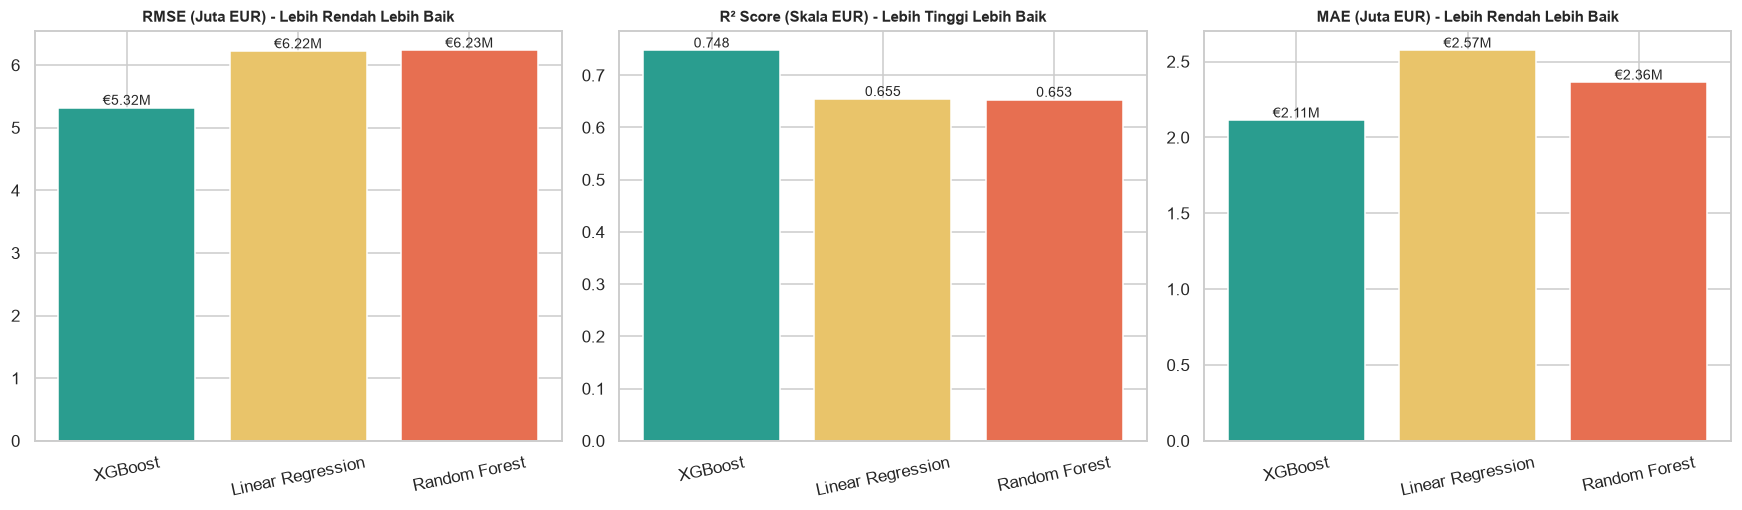

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
palette = ["#2a9d8f", "#e9c46a", "#e76f51"]

metrics_to_plot = [
    ("RMSE_EUR", "RMSE (Juta EUR) - Lebih Rendah Lebih Baik", 1e6),
    ("R2_EUR", "R² Score (Skala EUR) - Lebih Tinggi Lebih Baik", 1.0),
    ("MAE_EUR", "MAE (Juta EUR) - Lebih Rendah Lebih Baik", 1e6),
]

for ax, (col, title, scale) in zip(axes, metrics_to_plot):
    vals = eval_df[col] / scale
    bars = ax.bar(eval_df["Model"], vals, color=palette[: len(eval_df)])
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", rotation=12)
    for bar, val in zip(bars, vals):
        fmt = f"{val:.3f}" if col == "R2_EUR" else f"€{val:.2f}M"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), fmt, ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

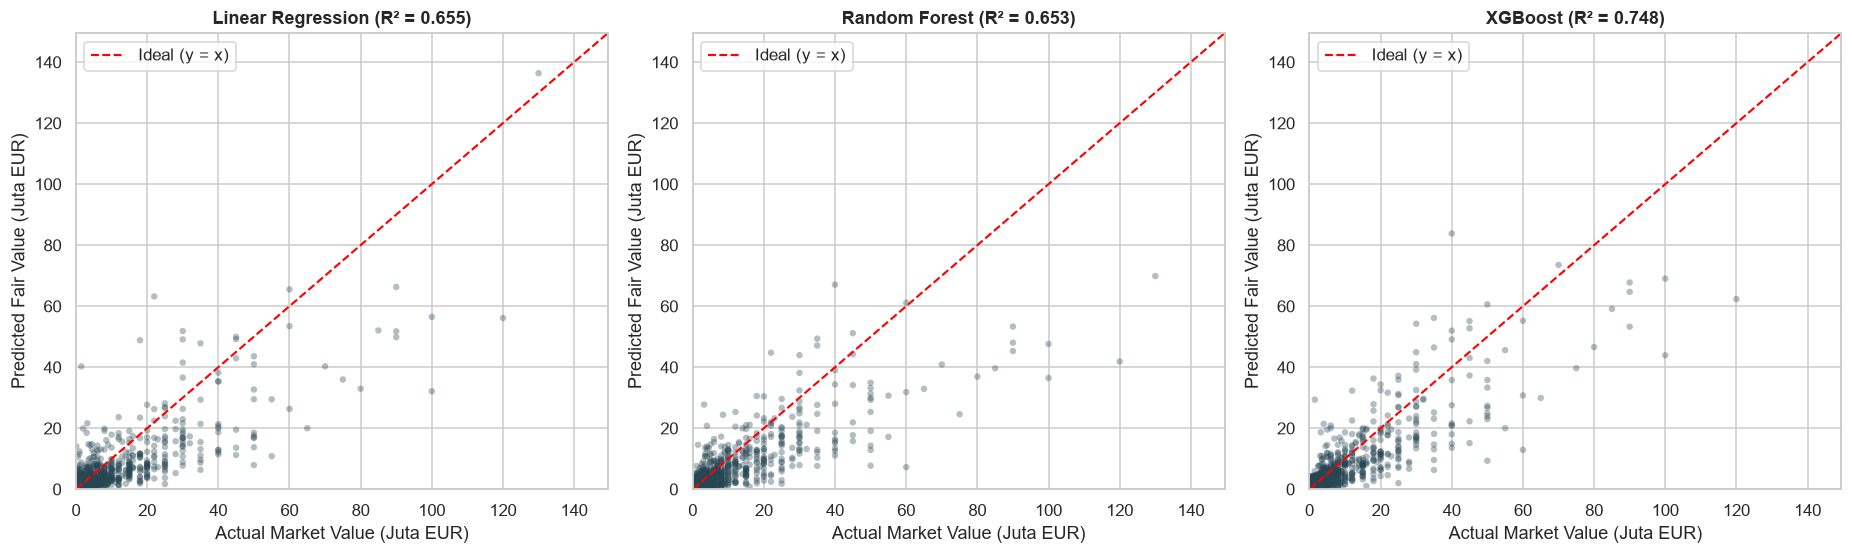

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
y_actual_m = y_test_eur / 1e6
max_val_m = max(y_actual_m.max(), max(v.max() for v in predictions_eur.values()) / 1e6) * 1.05

for ax, name in zip(axes, pipelines.keys()):
    y_pred_m = predictions_eur[name] / 1e6
    r2_val = eval_df.loc[eval_df["Model"] == name, "R2_EUR"].values[0]

    ax.scatter(y_actual_m, y_pred_m, alpha=0.35, s=18, color="#264653", edgecolors="none")
    ax.plot([0, max_val_m], [0, max_val_m], "r--", linewidth=1.4, label="Ideal (y = x)")
    ax.set_xlim(0, min(max_val_m, y_actual_m.max() * 1.15))
    ax.set_ylim(0, min(max_val_m, y_actual_m.max() * 1.15))
    ax.set_title(f"{name} (R² = {r2_val:.3f})", fontweight="bold")
    ax.set_xlabel("Actual Market Value (Juta EUR)")
    ax.set_ylabel("Predicted Fair Value (Juta EUR)")
    ax.legend()

plt.tight_layout()
plt.show()

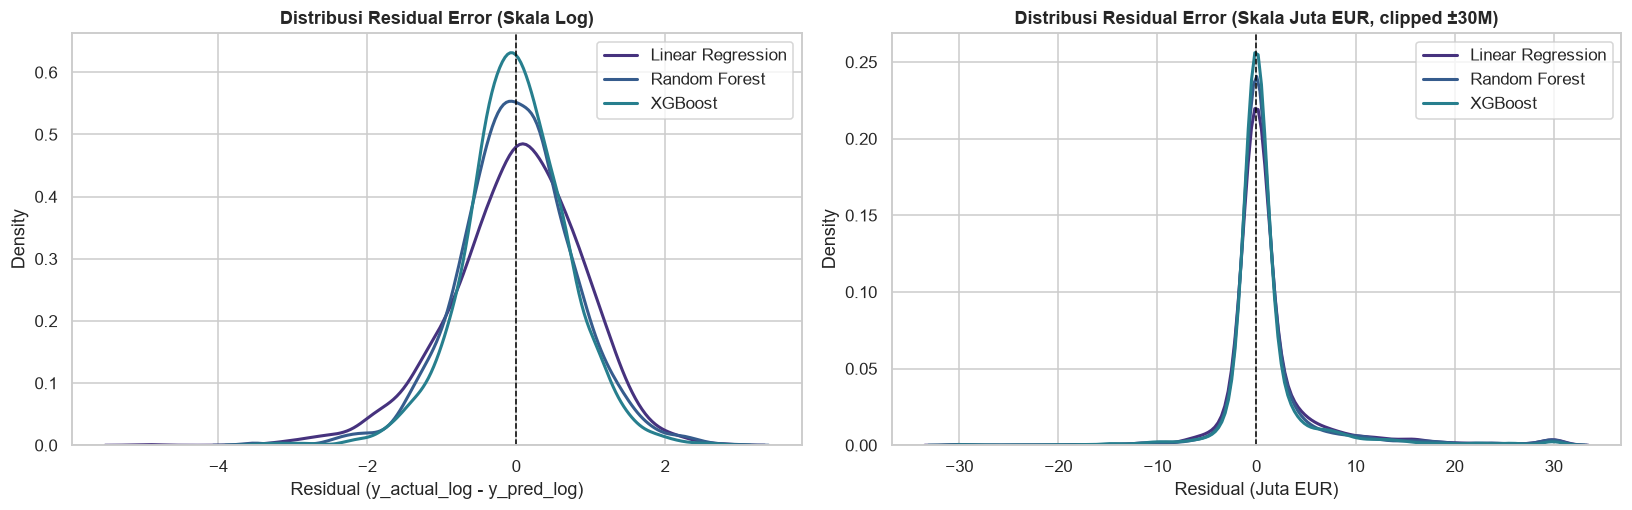

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

for name in pipelines.keys():
    res_log = y_test_log.to_numpy() - predictions_log[name]
    res_eur_m = (y_test_eur - predictions_eur[name]) / 1e6
    sns.kdeplot(res_log, ax=axes[0], label=name, linewidth=2)
    sns.kdeplot(np.clip(res_eur_m, -30, 30), ax=axes[1], label=name, linewidth=2)

axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Distribusi Residual Error (Skala Log)", fontweight="bold")
axes[0].set_xlabel("Residual (y_actual_log - y_pred_log)")
axes[0].legend()

axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Distribusi Residual Error (Skala Juta EUR, clipped ±30M)", fontweight="bold")
axes[1].set_xlabel("Residual (Juta EUR)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Ringkasan Temuan Bagian 3
- **Hyperparameter Tuning & Generalisasi:** Penerapan 5-fold `RandomizedSearchCV` pada **Random Forest** dan **XGBoost** berhasil menekan kesenjangan (*overfitting gap*) antara performa *train* dan *test* dengan membatasi kompleksitas pohon serta memperkuat regularisasi.
- **Komparasi Performa:** Model berbasis *tree ensemble* (**XGBoost Regressor** dan **Random Forest Regressor**) mengungguli **Linear Regression** secara signifikan pada skala log maupun skala Euro asli (`np.expm1`), karena mampu menangkap hubungan non-linear antara usia, menit bermain, statistik per-90, dan reputasi klub/liga.
- **Kualitas Residual:** Distribusi residual error pada model terbaik terpusat rapat di sekitar nol (`0`) dengan simpangan yang lebih kecil, serta sebaran *Actual vs Predicted* mengikuti garis diagonal $y = x$ jauh lebih baik dibanding *baseline* linear.

## Bagian 4: Feature Importance & Deteksi Undervalued

Bagian akhir memilih model terbaik berdasarkan skor evaluasi pada skala Euro, memvisualisasikan *feature importance* bawaan model, menyusun daftar pemain berstatus **Undervalued** (`Predicted_Fair_Value > Actual_Market_Value`), serta menyimpan model terbaik dan *preprocessing pipeline* ke folder `models/`.

Model terbaik terpilih: XGBoost (R2_EUR = 0.7476, RMSE_EUR = €5,318,746)


,feature,importance
0,is_top5_league,0.32
1,club_national_team_players,0.15
2,cl_appearances,0.06
3,league_group_BE1,0.05
4,age,0.04
5,league_group_SC1,0.04
6,contract_months_left,0.03
7,el_appearances,0.03
8,league_group_GB1,0.03
9,league_group_UKR1,0.03


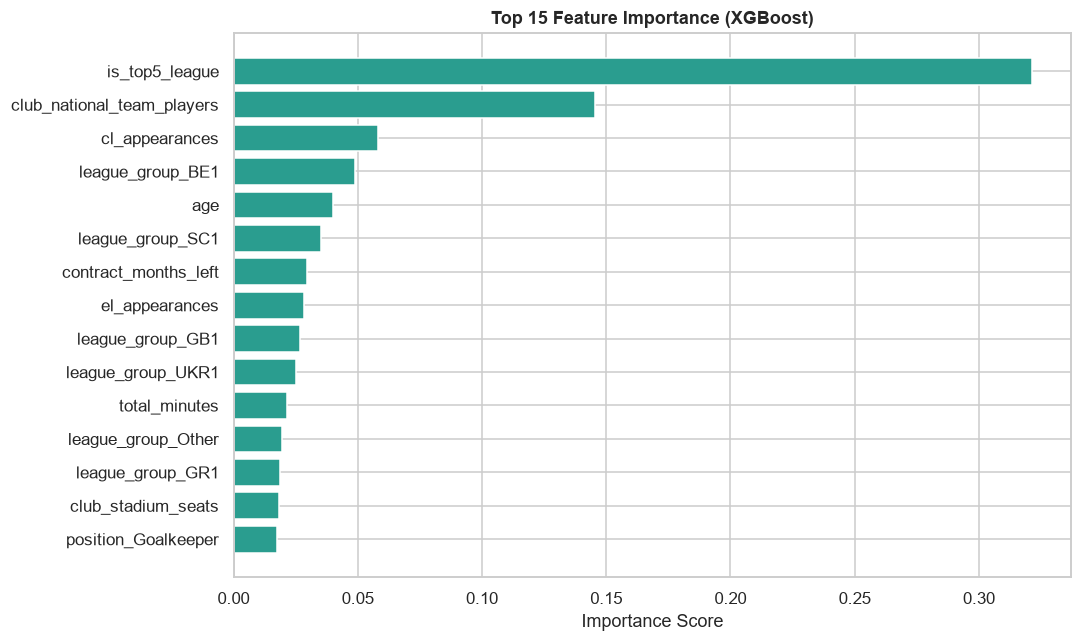

In [15]:
best_model_name = eval_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]
print(f"Model terbaik terpilih: {best_model_name} (R2_EUR = {eval_df.iloc[0]['R2_EUR']:.4f}, RMSE_EUR = €{eval_df.iloc[0]['RMSE_EUR']:,.0f})")

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_estimator = best_pipeline.named_steps["model"]
feature_names = fitted_preprocessor.get_feature_names_out()
clean_feature_names = [f.replace("num__", "").replace("cat__", "") for f in feature_names]

if hasattr(fitted_estimator, "feature_importances_"):
    importances = fitted_estimator.feature_importances_
else:
    importances = np.abs(fitted_estimator.coef_)

fi_df = (
    pd.DataFrame({"feature": clean_feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(fi_df.head(15))

plt.figure(figsize=(10, 6))
top15 = fi_df.head(15).sort_values("importance", ascending=True)
plt.barh(top15["feature"], top15["importance"], color="#2a9d8f")
plt.title(f"Top 15 Feature Importance ({best_model_name})", fontweight="bold")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

In [16]:
scouting_df = meta_test.copy().reset_index(drop=True)
scouting_df["age"] = X_test["age"].to_numpy().round(1)
scouting_df["position"] = X_test["position"].to_numpy()
scouting_df["league_group"] = X_test["league_group"].to_numpy()
scouting_df["Actual_Market_Value_EUR"] = y_test_eur
scouting_df["Predicted_Fair_Value_EUR"] = predictions_eur[best_model_name]
scouting_df["Valuation_Gap_EUR"] = (
    scouting_df["Predicted_Fair_Value_EUR"] - scouting_df["Actual_Market_Value_EUR"]
)
scouting_df["Undervalued_Pct"] = (
    scouting_df["Valuation_Gap_EUR"] / scouting_df["Actual_Market_Value_EUR"] * 100.0
)
scouting_df["Valuation_Status"] = np.where(
    scouting_df["Predicted_Fair_Value_EUR"] > scouting_df["Actual_Market_Value_EUR"],
    "Undervalued",
    "Overvalued",
)

print("Distribusi Status Valuasi pada Data Test:")
print(scouting_df["Valuation_Status"].value_counts().to_string())

undervalued_players = (
    scouting_df[scouting_df["Valuation_Status"] == "Undervalued"]
    .sort_values("Valuation_Gap_EUR", ascending=False)
    .reset_index(drop=True)
)

display_cols = [
    "name",
    "current_club_name",
    "league_group",
    "position",
    "age",
    "Actual_Market_Value_EUR",
    "Predicted_Fair_Value_EUR",
    "Valuation_Gap_EUR",
    "Undervalued_Pct",
]
print("\nTop 15 Pemain Undervalued Berdasarkan Selisih Valuasi Tertinggi (Data Test):")
display(undervalued_players[display_cols].head(15))

Distribusi Status Valuasi pada Data Test:
Valuation_Status
Undervalued    1046
Overvalued     1011

Top 15 Pemain Undervalued Berdasarkan Selisih Valuasi Tertinggi (Data Test):


,name,current_club_name,league_group,position,age,Actual_Market_Value_EUR,Predicted_Fair_Value_EUR,Valuation_Gap_EUR,Undervalued_Pct
0,Xavi Simons,RB Leipzig,L1,Midfield,23.10,"40,000,000.00","83,812,840.00","43,812,840.00",109.53
1,Jude Bellingham,Real Madrid,ES1,Midfield,22.90,"130,000,000.00","162,861,552.00","32,861,552.00",25.28
2,Leo Hjelde,Sunderland AFC,GB1,Defender,19.80,"1,500,000.00","29,381,984.00","27,881,984.00","1,858.80"
3,Jonathan David,Juventus FC,IT1,Attack,26.40,"30,000,000.00","54,241,772.00","24,241,772.00",80.81
4,Jeremie Frimpong,Liverpool FC,GB1,Defender,25.50,"35,000,000.00","56,150,596.00","21,150,596.00",60.43
5,Andriy Lunin,Real Madrid,ES1,Goalkeeper,27.30,"12,000,000.00","32,310,324.00","20,310,324.00",169.25
6,Wilson Odobert,Tottenham Hotspur,GB1,Attack,21.50,"18,000,000.00","36,291,808.00","18,291,808.00",101.62
7,Giovanni Reyna,Borussia Dortmund,L1,Midfield,23.50,"4,000,000.00","21,448,280.00","17,448,280.00",436.21
8,Patrick Roberts,Sunderland AFC,GB1,Attack,26.30,"3,200,000.00","18,665,608.00","15,465,608.00",483.30
9,Mathias Kvistgaarden,Norwich City,GB1,Attack,24.10,"6,000,000.00","20,911,864.00","14,911,864.00",248.53


In [17]:
best_model_path = MODELS_DIR / "best_model.joblib"
preprocessor_path = MODELS_DIR / "preprocessor.joblib"
all_models_path = MODELS_DIR / "all_models.joblib"
metadata_path = MODELS_DIR / "model_metadata.joblib"

joblib.dump(best_pipeline, best_model_path)
joblib.dump(fitted_preprocessor, preprocessor_path)
joblib.dump(pipelines, all_models_path)
joblib.dump(
    {
        "best_model_name": best_model_name,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "feature_cols": FEATURE_COLS,
        "evaluation_metrics": eval_df.to_dict(orient="records"),
        "best_params": best_params,
    },
    metadata_path,
)

for p in (best_model_path, preprocessor_path, all_models_path, metadata_path):
    print(f"Tersimpan: {p} ({p.stat().st_size / 1024:,.1f} KB)")

Tersimpan: ..\models\best_model.joblib (1,822.4 KB)
Tersimpan: ..\models\preprocessor.joblib (3.6 KB)
Tersimpan: ..\models\all_models.joblib (37,715.8 KB)
Tersimpan: ..\models\model_metadata.joblib (1.3 KB)


### Ringkasan Temuan Bagian 4
- **Faktor Pendorong Valuasi:** Grafik *feature importance* menunjukkan faktor reputasi/kekuatan klub (`club_national_team_players`, `club_stadium_seats`, `is_top5_league`), volume serta jam terbang (`total_minutes`, `cl_appearances`), serta profil usia (`age`) dan sisa kontrak (`contract_months_left`) menjadi penentu utama harga pasar pemain.
- **Radar Scouting Undervalued:** Tabel pemain *Undervalued* berhasil mengidentifikasi pemain pada data *test* dengan nilai wajar prediksi lebih tinggi dari harga pasar aktualnya beserta nominal selisih dalam Euro untuk mendukung proses *scouting* dan negosiasi klub.
- **Artefak Tersimpan:** Model terbaik, *preprocessor*, seluruh *pipeline* pembanding, serta metadata fitur telah disimpan ke folder `models/` menggunakan `joblib` dan siap diintegrasikan ke tahap *prototype* dashboard.